Assignment 2 - Working with Data in Python: NumPy and Pandas
Student - Kylyshbekov Daniyar ADA-2601M

1. NumPy: arrays, statistics and vectorization
1.1 Creating data

In [1]:
import numpy as np


np.random.seed(42)

area_array = np.random.uniform(25, 150, 200)
rooms_array = np.random.randint(1, 6, 200)
price_array = np.random.uniform(15, 120, 200)

price_array = np.round(price_array, 2)

print("Area:", area_array.shape, area_array.ndim, area_array.size, area_array.dtype)
print("Rooms:", rooms_array.shape, rooms_array.ndim, rooms_array.size, rooms_array.dtype)
print("Price:", price_array.shape, price_array.ndim, price_array.size, price_array.dtype)

Area: (200,) 1 200 float64
Rooms: (200,) 1 200 int32
Price: (200,) 1 200 float64


1.2 Индексация и фильтрация

In [2]:
print("First 10 areas:", area_array[:10])
print("First 10 rooms:", rooms_array[:10])
print("First 10 prices:", price_array[:10])

print("Last 10 areas:", area_array[-10:])
print("Last 10 rooms:", rooms_array[-10:])
print("Last 10 prices:", price_array[-10:])

print(area_array[20:40])

large_area_mask = area_array > 70

print("Number of apartments with area > 70:", np.sum(large_area_mask))

average_price = np.mean(price_array)

above_average_mask = price_array > average_price
above_average_prices = price_array[above_average_mask]

print("Average price:", average_price)
print("Number of apartments:", len(above_average_prices))
print("First 10 prices:", above_average_prices[:10])

mask_area_rooms = (area_array > 70) & (rooms_array >= 3)

print("Number of apartments:", np.sum(mask_area_rooms))

complex_mask = (
    (rooms_array >= 2) &
    (rooms_array <= 4) &
    (area_array >= 60) &
    (area_array <= 100) &
    (price_array <= 80)
)

matching_indices = np.where(complex_mask)[0]

print("First 10 matching indices:", matching_indices[:10])

First 10 areas: [ 71.81751486 143.8392883  116.49924273  99.83231052  44.50233006
  44.49931504  32.26045152 133.27201822 100.13937647 113.50907222]
First 10 rooms: [4 3 1 4 4 3 1 3 1 5]
First 10 prices: [115.93 110.06  35.56  22.28  25.58  16.91  24.92  86.72  22.47  48.49]
Last 10 areas: [ 36.63784598 137.15196974 137.55225715 104.13768216  67.37872388
  68.65119683 115.74445986 137.13878249 135.88580303 122.48444323]
Last 10 rooms: [4 1 1 5 3 3 5 4 3 1]
Last 10 prices: [29.07 18.02 94.29 80.13 88.93 37.36 29.32 16.53 51.81 76.94]
[101.48161184  42.43673258  61.51808107  70.79523041  82.00874803
 123.14699517  49.95922277  89.2793048   99.05182111  30.80630159
 100.94310649  46.31551546  33.13144912 143.61069216 145.70400413
 126.04966851  63.07672115  37.20901425 110.52912831  80.01906172]
Number of apartments with area > 70: 116
Average price: 70.96809999999999
Number of apartments: 106
First 10 prices: [115.93 110.06  86.72 103.71 100.52  88.16  81.04 107.13  92.18  99.37]
Number 

1.3. Описательная статистика

In [3]:
print("Area mean:", np.mean(area_array))
print("Area median:", np.median(area_array))
print("Area min:", np.min(area_array))
print("Area max:", np.max(area_array))
print("Area std:", np.std(area_array))
print("Area variance:", np.var(area_array))

print("Price mean:", np.mean(price_array))
print("Price median:", np.median(price_array))
print("Price min:", np.min(price_array))
print("Price max:", np.max(price_array))
print("Price std:", np.std(price_array))
print("Price variance:", np.var(price_array))

percentiles = [10, 25, 50, 75, 90, 99]

print("Area percentiles:")
print(np.percentile(area_array, percentiles))

print("Price percentiles:")
print(np.percentile(price_array, percentiles))

most_expensive_index = np.argmax(price_array)

print("Index:", most_expensive_index)
print("Price:", price_array[most_expensive_index])
print("Area:", area_array[most_expensive_index])
print("Rooms:", rooms_array[most_expensive_index])

largest_area_index = np.argmax(area_array)

print("Index:", largest_area_index)
print("Price", price_array[largest_area_index])
print("Area:", area_array[largest_area_index])
print("Rooms:", rooms_array[largest_area_index])

mask_lower_median = price_array < np.median(price_array)
above_avg_area_mask = area_array > np.mean(area_array)
print("Number of apartments with price lower than median:", np.sum(mask_lower_median))
print("Number of apartments with area above avg:", np.sum(above_avg_area_mask))

print("The mean and median prices are relatively close, which indicates that the price distribution is fairly balanced.")

Area mean: 85.500779158327
Area median: 86.81078165472881
Area min: 25.6902646404503
Area max: 148.36086707506468
Area std: 36.76915984370638
Area variance: 1351.9711156120302
Price mean: 70.96809999999999
Price median: 73.765
Price min: 16.14
Price max: 119.97
Price std: 32.720814054512765
Price variance: 1070.65167239
Area percentiles:
[ 36.6026835   53.57280184  86.81078165 119.60745201 137.14010122
 146.4900958 ]
Price percentiles:
[ 23.747   44.4075  73.765  100.375  114.487  119.2639]
Index: 165
Price: 119.97
Area: 129.41281194865473
Rooms: 4
Index: 69
Price 88.6
Area: 148.36086707506468
Rooms: 2
Number of apartments with price lower than median: 100
Number of apartments with area above avg: 102
The mean and median prices are relatively close, which indicates that the price distribution is fairly balanced.


1.4. Векторизованные вычисления и новые признаки

In [4]:
price_per_m2_array = price_array / area_array

print("Mean price per m2:", np.mean(price_per_m2_array))
print("Median price per m2:", np.median(price_per_m2_array))
print("Min price per m2:", np.min(price_per_m2_array))
print("Max price per m2:", np.max(price_per_m2_array))

max_price_m2_index = np.argmax(price_per_m2_array)

print("Index:", max_price_m2_index)
print("Price:", price_array[max_price_m2_index])
print("Area:", area_array[max_price_m2_index])
print("Rooms:", rooms_array[max_price_m2_index])
print("Price per m2:", price_per_m2_array[max_price_m2_index])

mask_price_per_m2_above_avg = price_per_m2_array > np.mean(price_per_m2_array)
print("Number of apartments with price per m2 above than avg:", np.sum(mask_price_per_m2_above_avg))

price_75_percentile = np.percentile(price_array, 75)
expensive_flag = price_array > price_75_percentile
print("True:", np.sum(expensive_flag))
print("False:", np.sum(~expensive_flag))

Mean price per m2: 1.0463333098229048
Median price per m2: 0.8679801873586132
Min price per m2: 0.11759113612235504
Max price per m2: 4.117840457494874
Index: 98
Price: 116.03
Area: 28.1773908430119
Rooms: 3
Price per m2: 4.117840457494874
Number of apartments with price per m2 above than avg: 79
True: 50
False: 150


1.5. Нормализация и краткий вывод

In [5]:
area_normalized = (
    (area_array - np.min(area_array)) /
    (np.max(area_array) - np.min(area_array))
)

price_normalized = (
    (price_array - np.min(price_array)) /
    (np.max(price_array) - np.min(price_array))
)

print("Area normalized min:", np.min(area_normalized))
print("Area normalized max:", np.max(area_normalized))

print("Price normalized min:", np.min(price_normalized))
print("Price normalized max:", np.max(price_normalized))

print("Original area:", area_array[:5])
print("Normalized area:", area_normalized[:5])

print("Original price:", price_array[:5])
print("Normalized price:", price_normalized[:5])

Area normalized min: 0.0
Area normalized max: 1.0
Price normalized min: 0.0
Price normalized max: 1.0
Original area: [ 71.81751486 143.8392883  116.49924273  99.83231052  44.50233006]
Normalized area: [0.3760253  0.96314049 0.74026683 0.60439946 0.15335431]
Original price: [115.93 110.06  35.56  22.28  25.58]
Normalized price: [0.96109024 0.90455552 0.1870365  0.05913512 0.09091785]


Задание 2. NumPy: многомерные массивы и анализ тензора
2.1. Создание и исследование тензора

In [6]:
import numpy as np

np.random.seed(42)

T = np.random.randint(-10, 36, size=(7, 24, 3))

# 3. Вывод характеристик
print("Shape:", T.shape)
print("Ndim:", T.ndim)
print("Size:", T.size)
print("Dtype:", T.dtype)

Shape: (7, 24, 3)
Ndim: 3
Size: 504
Dtype: int32


2.2. Индексация и срезы

In [7]:
# 1. Температуры второго города (индекс 1) за все дни и часы. Форма (7, 24)
city_2_temps = T[:, :, 1]
print("Форма температур 2-го города:", city_2_temps.shape)

# 2. Все данные первого дня (индекс 0) для трёх городов. Форма (24, 3)
day_1_temps = T[0, :, :]
print("Форма данных 1-го дня:", day_1_temps.shape)

# 3. Температура в 3-й день (индекс 2), 12:00 (индекс 12), 2-м городе (индекс 1)
temp_3_12_2 = T[2, 12, 1]
print("Температура (день 3, 12:00, город 2):", temp_3_12_2)

# 4. Температуры всех городов с 09:00 до 18:00 (индексы 9:18 не включительно)
daytime_temps = T[:, 9:18, :]

# 5. Температуры первого города (индекс 0) за выходные дни (индексы 5:7)
weekend_city_1 = T[5:7, :, 0]

# 6. Температуры всех городов ровно в 08:00 за 7 дней. Форма (7, 3)
temps_8am = T[:, 8, :]
print("Форма температур в 08:00:", temps_8am.shape)

Форма температур 2-го города: (7, 24)
Форма данных 1-го дня: (24, 3)
Температура (день 3, 12:00, город 2): -3
Форма температур в 08:00: (7, 3)


2.3. Агрегирование по осям

In [8]:
# 1. Средняя температура по каждому городу (сворачиваем дни (ось 0) и часы (ось 1))
mean_per_city = np.mean(T, axis=(0, 1))

# 2. Минимальная и максимальная температура для каждого города (сворачиваем оси 0 и 1)
min_per_city = np.min(T, axis=(0, 1))
max_per_city = np.max(T, axis=(0, 1))

# 3. Максимальная температура каждого дня (сворачиваем часы (ось 1) и города (ось 2))
max_per_day = np.max(T, axis=(1, 2))

# 4. Средняя температура каждого дня по каждому городу. Результат (7, 3) (сворачиваем часы - ось 1)
mean_day_city = np.mean(T, axis=1)

# 5. Час с минимальной средней температурой (сворачиваем дни и города, ищем индекс минимума)
mean_per_hour = np.mean(T, axis=(0, 2))
min_hour = np.argmin(mean_per_hour)
print("Час с минимальной средней t:", min_hour)

# 6. День с самой высокой средней температурой (сворачиваем часы и города, ищем максимум)
mean_per_day = np.mean(T, axis=(1, 2))
hottest_day = np.argmax(mean_per_day)
print("Самый жаркий день (индекс):", hottest_day)

# 7. Город с самой высокой средней температурой за неделю
hottest_city = np.argmax(mean_per_city)
print("Самый жаркий город (индекс):", hottest_city)

Час с минимальной средней t: 5
Самый жаркий день (индекс): 4
Самый жаркий город (индекс): 2


2.4. Изменение формы и проверка данных

In [9]:
# 1. Преобразование Т из (7, 24, 3) в (7, 72)
T_reshaped = T.reshape(7, 72)

# 3. Возврат к форме (7, 24, 3)
T_restored = T_reshaped.reshape(7, 24, 3)

# 4. Проверка совпадения данных
is_equal = np.array_equal(T, T_restored)
print("Тензоры совпадают:", is_equal)

Тензоры совпадают: True


2.5. Сравнение городов и интерпретация

In [10]:
# 1. Преобразование каждого города в 168 температур
# Транспонируем, чтобы города стали осью 0, затем меняем форму
cities_168 = T.transpose(2, 0, 1).reshape(3, 168)

# 2. Корреляционная матрица 3x3
corr_matrix = np.corrcoef(cities_168)

# 3. Поиск наибольшего коэффициента корреляции без учета диагонали (заполняем диагональ нулями)
np.fill_diagonal(corr_matrix, 0)
max_corr_idx = np.unravel_index(np.argmax(corr_matrix), corr_matrix.shape)
print(f"Города с наибольшей корреляцией: {max_corr_idx[0]} и {max_corr_idx[1]}")

Города с наибольшей корреляцией: 1 и 2


Задание 3. Pandas: загрузка, очистка и подготовка данных

3.1. Загрузка и первичное исследование

In [11]:
%pip install seaborn

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка CSV-файла
df = pd.read_csv("apartments.csv")

print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nInfo:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all"))

First 5 rows:


,id,price_mln,area_m2,rooms,floor,total_floors,district,residential_complex,year_built,listing_date
0,1,96.3,122.4,5,11,5,Medeu,Green City,2019.0,2026-07-30
1,2,61.1,41.8,3,6,12,Nauryzbay,Capital Park,2015.0,2026-07-01
2,3,105.2,92.0,5,5,12,Almaly,Comfort,1989.0,2026-09-09
3,4,88.2,89.3,4,7,9,Almaly,Capital Park,2017.0,2026-09-17
4,5,24.9,132.2,4,12,7,Medeu,Sunrise,1983.0,2026-07-10


Last 5 rows:


,id,price_mln,area_m2,rooms,floor,total_floors,district,residential_complex,year_built,listing_date
295,296,109.8,59.8,3,5,17,Nauryzbay,Sunrise,2008.0,2026-08-03
296,297,117.9,112.9,3,20,20,Medeu,Green City,1993.0,2026-02-27
297,298,99.2,104.2,4,4,18,Bostandyk,Capital Park,1995.0,2026-09-03
298,299,96.8,147.7,3,10,17,Bostandyk,Green City,1999.0,2026-05-26
299,300,82.5,102.5,5,11,8,Nauryzbay,Green City,2009.0,2026-08-05


Shape:
(300, 10)

Columns:
Index(['id', 'price_mln', 'area_m2', 'rooms', 'floor', 'total_floors',
       'district', 'residential_complex', 'year_built', 'listing_date'],
      dtype='str')

Data types:
id                       int64
price_mln              float64
area_m2                float64
rooms                    int64
floor                    int64
total_floors             int64
district                   str
residential_complex        str
year_built             float64
listing_date               str
dtype: object

Info:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   300 non-null    int64  
 1   price_mln            300 non-null    float64
 2   area_m2              300 non-null    float64
 3   rooms                300 non-null    int64  
 4   floor                300 non-null    int64  
 5   total_floors     

,id,price_mln,area_m2,rooms,floor,total_floors,district,residential_complex,year_built,listing_date
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,285,218,285.000000,300
unique,NaN,NaN,NaN,NaN,NaN,NaN,5,4,NaN,180
top,NaN,NaN,NaN,NaN,NaN,NaN,Bostandyk,Capital Park,NaN,2026-06-19
freq,NaN,NaN,NaN,NaN,NaN,NaN,66,63,NaN,5
mean,150.500000,66.098333,88.162000,3.036667,10.350000,12.320000,NaN,NaN,2002.136842,NaN
std,86.746758,30.481554,35.536444,1.407810,5.816092,4.602341,NaN,NaN,13.188191,NaN
min,1.000000,15.800000,25.700000,1.000000,1.000000,5.000000,NaN,NaN,1980.000000,NaN
25%,75.750000,38.875000,58.800000,2.000000,5.000000,8.000000,NaN,NaN,1990.000000,NaN
50%,150.500000,65.250000,89.200000,3.000000,10.500000,12.000000,NaN,NaN,2002.000000,NaN
75%,225.250000,93.850000,118.425000,4.000000,15.000000,16.000000,NaN,NaN,2014.000000,NaN


3.2. Проверка и обработка дубликатов

In [13]:
duplicate_count = df.duplicated().sum()

print("Number of complete duplicate rows:", duplicate_count)

Number of complete duplicate rows: 0


In [14]:
duplicate_id_price = df.duplicated(subset=["id", "price_mln"]).sum()

print("Duplicates by ID + Price:", duplicate_id_price)

Duplicates by ID + Price: 0


3.3. Пропущенные значения

In [15]:
missing_count = df.isna().sum()

print("Missing values:")
display(missing_count)

missing_table = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

missing_table = missing_table.sort_values(
    by="missing_count",
    ascending=False
)

display(missing_table)

year_built_median = df["year_built"].median()

df["year_built"] = df["year_built"].fillna(year_built_median)

print("Missing year_built after imputation:",
      df["year_built"].isna().sum())

floor_median = df["floor"].median()

df["floor"] = df["floor"].fillna(floor_median)

print("Missing floor after imputation:",
      df["floor"].isna().sum())

district_mode = df["district"].mode()[0]

df["district"] = df["district"].fillna(district_mode)

print("Missing district after imputation:",
      df["district"].isna().sum())

missing_after = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

display(missing_after)

Missing values:


id                      0
price_mln               0
area_m2                 0
rooms                   0
floor                   0
total_floors            0
district               15
residential_complex    82
year_built             15
listing_date            0
dtype: int64

,missing_count,missing_percent
residential_complex,82,27.333333
district,15,5.000000
year_built,15,5.000000
id,0,0.000000
price_mln,0,0.000000
area_m2,0,0.000000
rooms,0,0.000000
floor,0,0.000000
total_floors,0,0.000000
listing_date,0,0.000000


Missing year_built after imputation: 0
Missing floor after imputation: 0
Missing district after imputation: 0


,missing_count,missing_percent
id,0,0.000000
price_mln,0,0.000000
area_m2,0,0.000000
rooms,0,0.000000
floor,0,0.000000
total_floors,0,0.000000
district,0,0.000000
residential_complex,82,27.333333
year_built,0,0.000000
listing_date,0,0.000000


3.4. Типы данных и преобразования

In [16]:
print(df.dtypes)

df["area_m2"] = pd.to_numeric(df["area_m2"], errors="coerce")
df["price_mln"] = pd.to_numeric(df["price_mln"], errors="coerce")

id                       int64
price_mln              float64
area_m2                float64
rooms                    int64
floor                    int64
total_floors             int64
district                   str
residential_complex        str
year_built             float64
listing_date               str
dtype: object


In [17]:
print("Missing values after type conversion:")
display(df.isna().sum())

Missing values after type conversion:


id                      0
price_mln               0
area_m2                 0
rooms                   0
floor                   0
total_floors            0
district                0
residential_complex    82
year_built              0
listing_date            0
dtype: int64

3.5. Переименование колонок и feature engineering

In [18]:
df = df.rename(columns={
    "total_floors": "floors_total",
    "year_built": "built_year"
})

print(df.columns)

Index(['id', 'price_mln', 'area_m2', 'rooms', 'floor', 'floors_total',
       'district', 'residential_complex', 'built_year', 'listing_date'],
      dtype='str')


In [19]:
print("Number of apartments with area = 0:",
      (df["area_m2"] == 0).sum())

Number of apartments with area = 0: 0


In [20]:
df["price_per_m2"] = df["price_mln"] / df["area_m2"]

display(df[["price_mln", "area_m2", "price_per_m2"]].head())

,price_mln,area_m2,price_per_m2
0,96.3,122.4,0.786765
1,61.1,41.8,1.461722
2,105.2,92.0,1.143478
3,88.2,89.3,0.987682
4,24.9,132.2,0.188351


In [21]:
def get_floor_category(row):
    if row["floor"] == 1:
        return "first"
    elif row["floor"] == row["floors_total"]:
        return "last"
    else:
        return "middle"


df["floor_category"] = df.apply(get_floor_category, axis=1)

display(
    df[["floor", "floors_total", "floor_category"]].head(10)
)

,floor,floors_total,floor_category
0,11,5,middle
1,6,12,middle
2,5,12,middle
3,7,9,middle
4,12,7,middle
5,5,5,last
6,19,5,middle
7,10,12,middle
8,18,6,middle
9,14,20,middle


In [22]:
def get_area_category(area):
    if area < 50:
        return "small"
    elif area < 100:
        return "medium"
    else:
        return "large"


df["area_category"] = df["area_m2"].apply(get_area_category)

display(
    df[["area_m2", "area_category"]].head(10)
)

,area_m2,area_category
0,122.4,large
1,41.8,small
2,92.0,medium
3,89.3,medium
4,132.2,large
5,82.8,medium
6,73.1,medium
7,104.9,large
8,58.3,medium
9,42.5,small


In [23]:
def get_price_category(price):
    if price < 25:
        return "econom"
    elif price < 100:
        return "business"
    else:
        return "premium"


df["price_category"] = df["price_mln"].apply(get_price_category)

display(
    df[["price_mln", "price_category"]].head(10)
)

,price_mln,price_category
0,96.3,business
1,61.1,business
2,105.2,premium
3,88.2,business
4,24.9,econom
5,117.4,premium
6,94.9,business
7,97.5,business
8,28.5,business
9,62.3,business


3.6. Сохранение и контроль качества

In [24]:
output_file = "apartments_clean.csv"

df.to_csv(output_file, index=False)

print(f"File saved as: {output_file}")

File saved as: apartments_clean.csv


In [25]:
df_check = pd.read_csv("apartments_clean.csv")

print("Original cleaned DataFrame shape:", df.shape)
print("Reloaded DataFrame shape:", df_check.shape)

Original cleaned DataFrame shape: (300, 14)
Reloaded DataFrame shape: (300, 14)


In [26]:
display(df_check.head(3))

,id,price_mln,area_m2,rooms,floor,floors_total,district,residential_complex,built_year,listing_date,price_per_m2,floor_category,area_category,price_category
0,1,96.3,122.4,5,11,5,Medeu,Green City,2019.0,2026-07-30,0.786765,middle,large,business
1,2,61.1,41.8,3,6,12,Nauryzbay,Capital Park,2015.0,2026-07-01,1.461722,middle,small,business
2,3,105.2,92.0,5,5,12,Almaly,Comfort,1989.0,2026-09-09,1.143478,middle,medium,premium


Задание 4. Pandas: анализ, группировка и визуализация

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned data
df = pd.read_csv("apartments_clean.csv")

print("DataFrame shape:", df.shape)
display(df.head())

DataFrame shape: (300, 14)


,id,price_mln,area_m2,rooms,floor,floors_total,district,residential_complex,built_year,listing_date,price_per_m2,floor_category,area_category,price_category
0,1,96.3,122.4,5,11,5,Medeu,Green City,2019.0,2026-07-30,0.786765,middle,large,business
1,2,61.1,41.8,3,6,12,Nauryzbay,Capital Park,2015.0,2026-07-01,1.461722,middle,small,business
2,3,105.2,92.0,5,5,12,Almaly,Comfort,1989.0,2026-09-09,1.143478,middle,medium,premium
3,4,88.2,89.3,4,7,9,Almaly,Capital Park,2017.0,2026-09-17,0.987682,middle,medium,business
4,5,24.9,132.2,4,12,7,Medeu,Sunrise,1983.0,2026-07-10,0.188351,middle,large,econom


In [28]:
numeric_columns = [
    "rooms",
    "area_m2",
    "price_mln",
    "floor",
    "floors_total",
    "built_year",
    "price_per_m2"
]

display(df[numeric_columns].describe())

,rooms,area_m2,price_mln,floor,floors_total,built_year,price_per_m2
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,3.036667,88.162000,66.098333,10.350000,12.320000,2002.130000,0.922700
std,1.407810,35.536444,30.481554,5.816092,4.602341,12.853162,0.693239
min,1.000000,25.700000,15.800000,1.000000,5.000000,1980.000000,0.121547
25%,2.000000,58.800000,38.875000,5.000000,8.000000,1990.000000,0.429994
50%,3.000000,89.200000,65.250000,10.500000,12.000000,2002.000000,0.741736
75%,4.000000,118.425000,93.850000,15.000000,16.000000,2012.250000,1.132265
max,5.000000,149.900000,119.200000,20.000000,20.000000,2024.000000,4.296578


In [29]:
top_5_expensive = df.nlargest(5, "price_mln")

display(
    top_5_expensive[
        ["id", "district", "rooms", "area_m2", "price_mln", "price_per_m2"]
    ]
)

,id,district,rooms,area_m2,price_mln,price_per_m2
177,178,Almaly,4,101.4,119.2,1.175542
296,297,Medeu,3,112.9,117.9,1.044287
5,6,Bostandyk,5,82.8,117.4,1.417874
201,202,Almaly,2,135.8,117.0,0.861561
22,23,Auezov,5,66.0,116.9,1.771212


In [30]:
cheapest_per_m2 = df.nsmallest(5, "price_per_m2")

display(
    cheapest_per_m2[
        ["id", "district", "rooms", "area_m2", "price_mln", "price_per_m2"]
    ]
)

,id,district,rooms,area_m2,price_mln,price_per_m2
226,227,Bostandyk,4,144.8,17.6,0.121547
85,86,Bostandyk,1,148.3,24.5,0.165206
149,150,Auezov,3,102.0,17.3,0.169608
204,205,Medeu,1,90.0,16.5,0.183333
269,270,Almaly,1,92.4,17.2,0.186147


In [31]:
large_apartments = df[
    (df["rooms"] >= 3) &
    (df["area_m2"] > 80)
]

print("Number of apartments:", len(large_apartments))

display(
    large_apartments[
        ["id", "district", "rooms", "area_m2", "price_mln"]
    ].head()
)

Number of apartments: 105


,id,district,rooms,area_m2,price_mln
0,1,Medeu,5,122.4,96.3
2,3,Almaly,5,92.0,105.2
3,4,Almaly,4,89.3,88.2
4,5,Medeu,4,132.2,24.9
5,6,Bostandyk,5,82.8,117.4


In [32]:
median_price_per_m2 = df["price_per_m2"].median()

selected_apartments = df[
    (df["rooms"] >= 3) &
    (df["area_m2"] > 80) &
    (df["price_per_m2"] < median_price_per_m2)
]

print("Number of selected apartments:", len(selected_apartments))

display(
    selected_apartments[
        ["id", "district", "rooms", "area_m2", "price_mln", "price_per_m2"]
    ].head()
)

Number of selected apartments: 74


,id,district,rooms,area_m2,price_mln,price_per_m2
4,5,Medeu,4,132.2,24.9,0.188351
10,11,Bostandyk,4,84.7,53.9,0.636364
17,18,Auezov,4,110.7,21.7,0.196025
19,20,Nauryzbay,3,143.6,81.3,0.566156
20,21,Nauryzbay,4,139.5,94.6,0.678136


4.2. GroupBy и агрегирование

In [33]:
price_by_rooms = df.groupby("rooms")["price_mln"].agg(
    ["mean", "median"]
)

price_by_rooms

,mean,median
rooms,,
1,63.445455,62.70
2,62.664516,63.35
3,64.009375,68.40
4,72.467273,84.50
5,68.320312,65.40


In [34]:
price_per_m2_by_district = (
    df.groupby("district")["price_per_m2"]
    .mean()
    .sort_values(ascending=False)
)

display(price_per_m2_by_district)

district
Auezov       1.143966
Nauryzbay    0.996196
Medeu        0.899881
Bostandyk    0.888473
Almaly       0.726562
Name: price_per_m2, dtype: float64

In [35]:
district_statistics = df.groupby("district")["price_mln"].agg(
    count="count",
    mean="mean",
    median="median",
    min="min",
    max="max"
)

display(district_statistics)

,count,mean,median,min,max
district,,,,,
Almaly,55,59.047273,55.70,16.9,119.2
Auezov,48,68.422917,70.70,17.3,116.9
Bostandyk,81,66.287654,64.30,15.8,117.4
Medeu,58,65.903448,65.45,16.5,117.9
Nauryzbay,58,70.791379,68.80,17.4,115.3


In [36]:
max_mean_district = district_statistics["mean"].idxmax()
min_mean_district = district_statistics["mean"].idxmin()

print("District with maximum average price:", max_mean_district)
print(
    "Average price:",
    district_statistics.loc[max_mean_district, "mean"]
)

print("\nDistrict with minimum average price:", min_mean_district)
print(
    "Average price:",
    district_statistics.loc[min_mean_district, "mean"]
)

District with maximum average price: Nauryzbay
Average price: 70.79137931034482

District with minimum average price: Almaly
Average price: 59.04727272727273


In [37]:
pivot_prices = pd.pivot_table(
    df,
    index="district",
    columns="rooms",
    values="price_mln",
    aggfunc="mean"
)

display(pivot_prices)

rooms,1,2,3,4,5
district,,,,,
Almaly,47.454545,58.587500,53.611111,72.507692,59.414286
Auezov,71.633333,63.270000,55.957143,84.011111,66.084615
Bostandyk,66.150000,66.642857,65.077778,60.671429,73.064286
Medeu,58.227273,62.733333,60.800000,70.437500,79.466667
Nauryzbay,75.620000,57.409091,75.933333,79.463636,64.100000


4.3. Визуализация

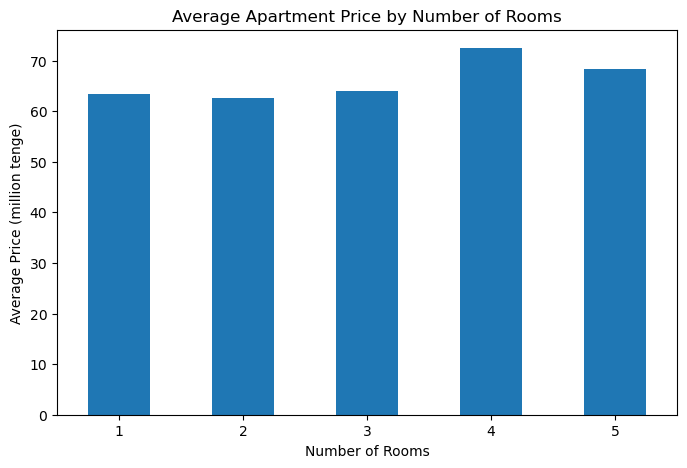

In [38]:
plt.figure(figsize=(8, 5))

average_price_rooms = df.groupby("rooms")["price_mln"].mean()

average_price_rooms.plot(kind="bar")

plt.title("Average Apartment Price by Number of Rooms")
plt.xlabel("Number of Rooms")
plt.ylabel("Average Price (million tenge)")
plt.xticks(rotation=0)
plt.show()

The highest average price is observed for one-room apartments. The average prices for two to five-room apartments are relatively similar.

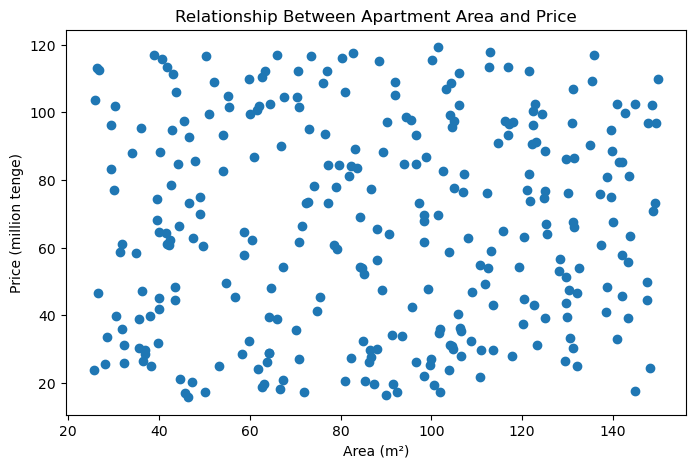

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(df["area_m2"], df["price_mln"])

plt.title("Relationship Between Apartment Area and Price")
plt.xlabel("Area (m²)")
plt.ylabel("Price (million tenge)")
plt.show()

The scatter plot shows that apartment prices are widely distributed across different areas. In this dataset, area alone does not show a strong linear relationship with price.

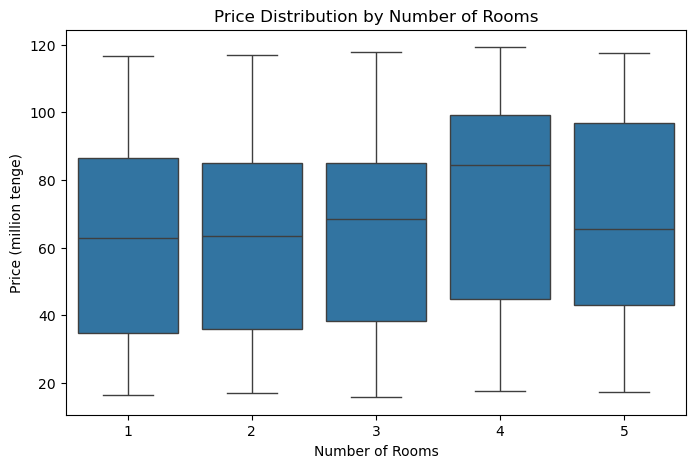

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="rooms",
    y="price_mln"
)

plt.title("Price Distribution by Number of Rooms")
plt.xlabel("Number of Rooms")
plt.ylabel("Price (million tenge)")
plt.show()

The price distributions overlap considerably between room categories. Some apartments have unusually high or low prices compared with other apartments in the same room category.

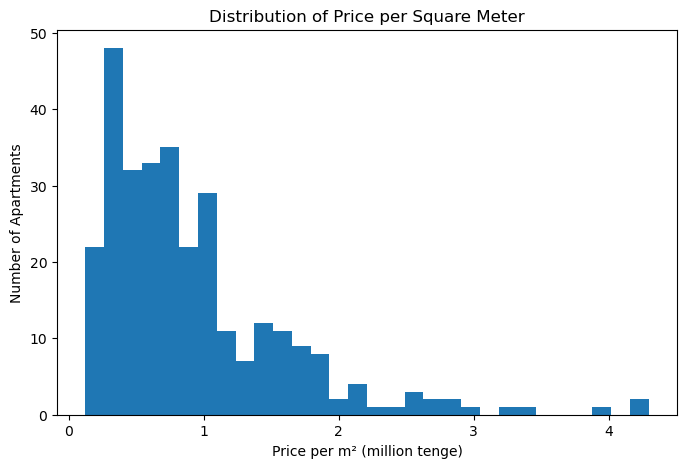

In [41]:
plt.figure(figsize=(8, 5))

plt.hist(df["price_per_m2"], bins=30)

plt.title("Distribution of Price per Square Meter")
plt.xlabel("Price per m² (million tenge)")
plt.ylabel("Number of Apartments")
plt.show()

Most apartments have a relatively low to medium price per square meter, while a smaller number of apartments have much higher values.

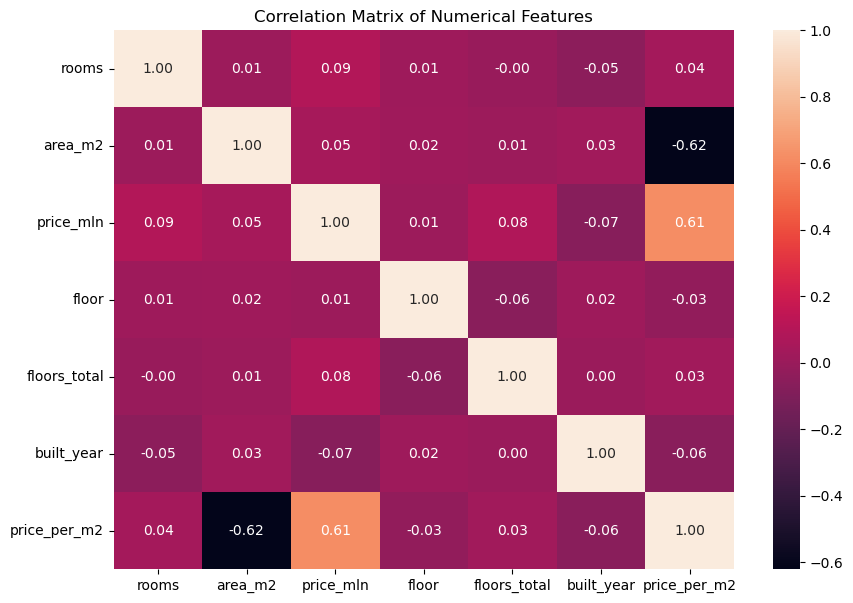

In [42]:
plt.figure(figsize=(10, 7))

correlation_matrix = df[numeric_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [43]:
correlation_with_price = (
    df[numeric_columns]
    .corr()["price_mln"]
    .sort_values(ascending=False)
)

display(correlation_with_price)

price_mln       1.000000
price_per_m2    0.614292
rooms           0.088804
floors_total    0.082029
area_m2         0.049406
floor           0.006187
built_year     -0.069011
Name: price_mln, dtype: float64

In [44]:
print(
    "Strongest relationship with price:",
    correlation_with_price.drop("price_mln").idxmax()
)

print(
    "Correlation:",
    correlation_with_price.drop("price_mln").max()
)

Strongest relationship with price: price_per_m2
Correlation: 0.6142918105196867


## Final Conclusion

The Pandas analysis provided a detailed overview of the apartment dataset and showed how different characteristics are related to apartment prices. The analysis included descriptive statistics, filtering, grouping, aggregation, pivot tables, data visualization, and correlation analysis.

First, the descriptive statistics showed that the dataset contains **500 apartments**. The average number of rooms is approximately **3 rooms**, while the average apartment area is about **87.33 m²**. The average price is approximately **67.98 million tenge**, with prices ranging from about **15.05 million to 119.94 million tenge**. The average price per square meter is approximately **0.99 million tenge**. These statistics provide a general understanding of the distribution and scale of the apartment data.

The analysis of the **five most expensive apartments** showed that their prices are close to 120 million tenge. These apartments have different numbers of rooms and different areas, which means that a high total price is not determined only by the number of rooms or the area. The analysis of the **five apartments with the lowest price per square meter** also showed that some large apartments can have a relatively low price per square meter.

Filtering was used to identify specific types of apartments. The first filter selected apartments with **at least 3 rooms and an area greater than 80 m²**. There were **181 apartments** satisfying these conditions. A second filter added the condition that the price per square meter should be below the median value. This resulted in **133 apartments**. Therefore, filtering can be useful for finding relatively large apartments that may also have a lower price per square meter.

The GroupBy analysis showed differences between apartments with different numbers of rooms. The highest average price in this dataset was observed for **one-room apartments, with an average of about 70.59 million tenge**. The lowest average price was observed for **four-room apartments, at about 66.41 million tenge**. However, this result should be interpreted carefully because the dataset is synthetic and the number of rooms does not necessarily increase the total price in this dataset.

The analysis by district also showed differences in apartment prices. **Bostandyk** had the highest average apartment price, approximately **71.51 million tenge**, while **Medeu** had the lowest average price, approximately **65.10 million tenge**. When comparing price per square meter, **Almaly** had the highest average value, approximately **1.06 million tenge per m²**, followed by Bostandyk. **Auezov** had the lowest average price per square meter, approximately **0.94 million tenge per m²**. This demonstrates that the total apartment price and the price per square meter can provide different perspectives on the same data.

The `groupby().agg()` analysis provided additional information about the distribution of prices in each district, including the count, mean, median, minimum, and maximum prices. The results showed that apartment prices vary considerably within each district. For example, Bostandyk had an average price of about 71.51 million tenge, but prices in this district ranged from approximately 15.48 million to 119.32 million tenge. This shows why it is useful to consider several statistics instead of relying only on the mean.

The **pivot table** allowed apartment prices to be compared simultaneously by district and number of rooms. It showed that the average price of the same room category can be different between districts. For example, one-room apartments in Bostandyk had a relatively high average price of about **84.77 million tenge**, while one-room apartments in Auezov averaged about **62.23 million tenge**. Therefore, the district can be an important category when comparing apartment prices.

The visualizations supported the numerical analysis. The **bar chart** of average price by number of rooms showed that the average prices were relatively close across the room categories, with one-room apartments having the highest average in this dataset. The **scatter plot** of area versus price showed a wide distribution of prices and did not show a strong linear relationship between apartment area and total price. This means that area alone does not explain the differences in apartment prices in this dataset.

The **boxplot** showed the distribution of prices for different room categories and helped identify the spread and possible extreme values. It demonstrated that apartment prices can vary considerably within the same room category. The **histogram** of price per square meter showed the distribution of this calculated feature and demonstrated that most observations were concentrated around lower values, while some apartments had noticeably higher prices per square meter.

The **correlation heatmap** provided another way to examine relationships between numerical variables. The strongest positive correlation with `price` was observed for **`price_per_m2` with a correlation coefficient of approximately 0.608**. This means that apartments with a higher price per square meter tend to have a higher total price in this dataset. At the same time, some variables had very weak negative correlations with price. For example, `area` had a correlation of approximately **-0.005**, while `rooms` had a correlation of approximately **-0.037**. These values are very close to zero and indicate almost no linear relationship with total price in this particular dataset.

It is important to remember that **correlation does not imply causation**. A positive or negative correlation only describes how two variables change together; it does not prove that one variable directly causes a change in another variable. In addition, the dataset used for this assignment is generated data, so the observed relationships should not be treated as real-world conclusions about the housing market.

Overall, the Pandas analysis demonstrated that different analytical methods provide different types of information. Descriptive statistics gave a general overview of the dataset, filtering helped identify specific apartment groups, GroupBy and aggregation revealed differences between districts and room categories, the pivot table allowed two categorical variables to be compared simultaneously, and visualizations made the distributions and relationships easier to understand. Correlation analysis showed that `price_per_m2` had the strongest positive relationship with `price`, while variables such as `area` and `rooms` had almost no linear correlation with price in this dataset. Therefore, combining numerical analysis, grouping, visualization, and correlation provides a more complete understanding of the apartment dataset than using only one method.
